# Cancer: T-cell marker enrichment across correction methods

Replicates the **T cells near versus far from malignant cells** analysis in Bilous et al., adapted to the final Syndri annotations and corrected matrices. Each dot is one **gene set × tissue slice × method**. Color is GSEA NES; area is −log10 FDR. Positive NES means enrichment near malignant cells after reversing CD28's log fold change, as in the reference. This is not a heatmap of average expression.

**Sources:** [Bilous et al., Nature Methods (2026)](https://doi.org/10.1038/s41592-026-03089-8); published Supplementary Tables 3–4, saved under `figures/resources/bilous2026`. Reference implementation: `Bilous2026/workflow/notebooks/xenium/1-xenium_decontamination_comparison_logreg.ipynb`, `get_df_gsea` and final GSEA cell, plus `workflow/scripts/xenium/contamination_metrics_diffexpr_sample.py`.

**Workflow:** filter genes expressed in ≥5 cells, then cells with ≥10 counts and ≥5 genes; define proximity on QC-passing **raw** cells and retain that assignment across methods; normalize each method to its median positive library size and log1p; Wilcoxon near versus far within pooled T-cell subtypes (≥30 cells in each group); preranked GSEA on log fold changes, custom sets, `min_size=1` (equivalent to the source’s `min_size=0` after empty sets are excluded; installed GSEApy requires ≥1), 1,000 permutations, seed 123. Missing data or untestable sets are gray ×, not zero enrichment.

**Adaptations:** Xenium uses 15 µm centroid proximity, matching Bilous. CosMx uses the existing 50-pixel neighborhood and the published lung marker sets intersected with measured genes. The image's 5 µm label describes Xenium segmentation expansion, not the neighbor radius; it is not applied to CosMx. Syndri uses the metric configuration: cell-type-specific target fraction 0.5, probability scaling with power 2, minimum probability 0.5. Only current `celladmix_k1p5ct` matrices are used; the old 10-factor breast pilot is excluded. No separate supervised ResolVI matrices are available in the configured results.

Run with the **rctd** Python environment (Scanpy, GSEApy). Caches are keyed by settings, source file metadata and marker tables. Existing results are never overwritten. Loading/DE/GSEA runs slice-by-slice; reruns reuse completed caches.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import sys, json, hashlib, re, gc, warnings
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import gseapy as gp
import h5py
from scipy import sparse
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from IPython.display import display

PROJECT = Path('/home/jwinchel/Syndri')
DATA_ROOT = Path('/work/magroup/skrieger/Syndri/data/datasets')
RESOURCE_DIR = PROJECT / 'figures/resources/bilous2026'
sys.path.insert(0, str(PROJECT / 'eval'))
from metrics_eval import cleaned_counts_for_removed_fraction_maybe_grouped

DATASETS = ['nsclc_cosmx','breast_xenium']
SLICE_SUBSETS = {}  # e.g. {'breast_xenium': ['GSM9509163_breast_breast_B11_B11_rctd_annotated']}
METHODS = ['Raw', 'ResolVI', 'ovrlpy 0.5', 'ovrlpy 0.7', 'SPLIT', 'CellAdmix', 'Syndri']
COLORS = {'Raw': '#5cafe0', 'ResolVI': '#9046ad', 'ovrlpy 0.5': '#ff953e',
          'ovrlpy 0.7': '#ffdf71', 'SPLIT': '#20b1a9', 'CellAdmix': '#d87ba3', 'Syndri': '#4056a1'}
MIN_COUNTS, MIN_GENES, MIN_CELLS_PER_GENE = 10, 5, 5
MIN_GROUP_SIZE = 30  # Skip DE/GSEA if either near or far has fewer QC-passing T cells.
NORMALIZE_TARGET = None  # Bilous uses Scanpy's median-library-size default; set 10_000 explicitly if desired.
PERMUTATIONS, SEED, THREADS = 1000, 123, 4
SYNDRI_TARGET = 0.5
CLEAN_ARGS = SimpleNamespace(cell_type_specific_removal=True, cleaning_mode='probability_scale',
    probability_transform='power', probability_power=2., clean_prob_threshold=0.5)
OUTPUT_ROOT = PROJECT / 'figures/outputs/cancer_tcell_enrichment'
SHOW_SAMPLE_LABELS = True

CONFIG = {
    'breast_xenium': dict(label='harmony_cell_type', xy=['x_centroid', 'y_centroid'],
        radius=15., units='µm', title='Breast Xenium', marker_file='Xenium_hBreast_v1_metadata_DB.csv',
        gene_column='Genes', tcell=['CD4-positive, alpha-beta memory T cell', 'cytotoxic T cell', 'natural T-regulatory cell'], malignant=['malignant cell']),
    'nsclc_cosmx': dict(label='cell_type_harmonized', xy=['CenterX_global_px', 'CenterY_global_px'],
        radius=50., units='pixels', title='NSCLC CosMx', marker_file='Xenium_hLung_v1_metadata_DB.csv',
        gene_column='Gene', tcell=['T CD4+', 'T CD8+', 'Treg'], malignant=['Malignant']),
}
TERMS = ['T cell', 'canonical T cell marker', 'cytotoxic T cell', 'epithelial cell',
         'exhausted T cell', 'fibroblast', 'immune response', 'malignant cell', 'proliferation', 'regulatory T cell']
EXTERNAL = {
    'ResolVI': ('resolvi', 'resolvi_corrected_counts'),
    'ovrlpy 0.5': ('ovrlpy_pixel_correction', 'ovrlpy_corrected_counts_vsi_lt_0_5'),
    'ovrlpy 0.7': ('ovrlpy_pixel_correction', 'ovrlpy_corrected_counts_vsi_lt_0_7'),
    'CellAdmix': ('celladmix_k1p5ct', 'celladmix_corrected_counts'),
}
plt.rcParams.update({'pdf.fonttype': 42, 'svg.fonttype': 'none', 'font.size': 10})


## Inputs and published marker sets
The availability table reports missing matrices explicitly. Cell IDs and gene names are aligned to the final AnnData; unmatched cells are excluded, never filled with raw counts. Gene-set coverage is exported for each test. Changing dataset, method, slice, or cleaning settings creates a separate output directory.

In [2]:
def file_signature(path):
    path = Path(path)
    st = path.stat()
    return {'path': str(path.resolve()), 'size': st.st_size, 'mtime_ns': st.st_mtime_ns}


def read_metadata(path):
    with h5py.File(path, 'r') as f:
        return ad.io.read_elem(f['obs']), ad.io.read_elem(f['var'])


def read_matrix(path, layer=None):
    # Read one matrix only: loading an entire h5ad also loads large probability layers.
    with h5py.File(path, 'r') as f:
        key = 'X' if layer is None else f'layers/{layer}'
        if key not in f:
            raise KeyError(f'{path}: missing {key}')
        return sparse.csr_matrix(ad.io.read_elem(f[key]))


def natural_key(text):
    return [int(s) if s.isdigit() else s.lower() for s in re.split(r'(\d+)', text)]


def sample_label(stem):
    if '_breast_breast_' in stem:
        return stem.split('_breast_breast_')[1].removesuffix('_rctd_annotated')
    return stem.removeprefix('st_integrated_slice-')


marker_sets, records, inputs = {}, [], {}
for dataset in DATASETS:
    cfg = CONFIG[dataset]
    table = pd.read_csv(RESOURCE_DIR / cfg['marker_file'])
    marker_sets[dataset] = {term: sorted(set(table.loc[table.Annotation_DB.eq(term), cfg['gene_column']].dropna())) for term in TERMS}
    files = sorted((DATA_ROOT / dataset / 'results/final').glob('*.h5ad'), key=lambda p: natural_key(sample_label(p.stem)))
    if dataset in SLICE_SUBSETS:
        wanted = set(SLICE_SUBSETS[dataset])
        assert wanted <= {p.stem for p in files}, f'Unknown slices for {dataset}'
        files = [p for p in files if p.stem in wanted]
    assert files, f'No final inputs for {dataset}'
    inputs[dataset] = files
    for path in files:
        for method in METHODS:
            source = path if method not in EXTERNAL else path.parent.parent / 'competitors' / EXTERNAL[method][0] / path.name
            records.append(dict(dataset=dataset, slice=path.stem, sample=sample_label(path.stem), method=method,
                                source=str(source), available=source.is_file()))
manifest = pd.DataFrame(records)
display(manifest.groupby(['dataset','method'], sort=False).available.agg(['sum','size']).rename(columns={'sum':'available','size':'total'}))
settings = dict(version=3, symbol_mapping_version=2, datasets=DATASETS, methods=METHODS, subsets=SLICE_SUBSETS, config=CONFIG,
                min_counts=MIN_COUNTS, min_genes=MIN_GENES, min_cells_per_gene=MIN_CELLS_PER_GENE,
                min_group_size=MIN_GROUP_SIZE, normalize_target=NORMALIZE_TARGET, permutations=PERMUTATIONS,
                seed=SEED, syndri_target=SYNDRI_TARGET, cleaning=vars(CLEAN_ARGS),
                sources=[file_signature(p) for p in sorted(set(manifest.loc[manifest.available, 'source']))],
                marker_sha256={d: hashlib.sha256((RESOURCE_DIR / CONFIG[d]['marker_file']).read_bytes()).hexdigest() for d in DATASETS},
                versions={'scanpy': sc.__version__, 'gseapy': gp.__version__},
                evaluator_sha256=hashlib.sha256((PROJECT/'eval/metrics_eval.py').read_bytes()).hexdigest())
run_id = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:16]
RUN_DIR = OUTPUT_ROOT / run_id
RUN_DIR.mkdir(parents=True, exist_ok=True)
if not (RUN_DIR/'settings.json').exists():
    with (RUN_DIR/'settings.json').open('x') as f: json.dump(settings, f, indent=2)
if not (RUN_DIR/'inputs.csv').exists(): manifest.to_csv(RUN_DIR/'inputs.csv', index=False, mode='x')
print('Results:', RUN_DIR)


available  total
dataset       method                      
nsclc_cosmx   Raw                 8      8
              ResolVI             7      8
              ovrlpy 0.5          8      8
              ovrlpy 0.7          8      8
              SPLIT               8      8
              CellAdmix           6      8
              Syndri              8      8
breast_xenium Raw                19     19
              ResolVI            19     19
              ovrlpy 0.5         19     19
              ovrlpy 0.7         19     19
              SPLIT              19     19
              CellAdmix           0     19
              Syndri             19     19

Results: /home/jwinchel/Syndri/figures/outputs/cancer_tcell_enrichment/128b3a3c41b56a06


/tmp/ipykernel_3412565/2297371558.py:56: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  versions={'scanpy': sc.__version__, 'gseapy': gp.__version__},


## Differential expression and GSEA
Raw QC fixes the spatial labels for each slice, matching the reference's use of precomputed raw-cell metadata for corrected counts. Each method then has its own expression QC. A sample must retain at least 30 near and 30 far T cells. The lung sets used on CosMx are a cross-panel adaptation; inspect `marker_coverage.csv` before interpreting absent programs.

Normalization follows the source code (`target_sum=None`) rather than the 10k normalization used in the separate cell-separation metrics. All measured, QC-retained genes form the ranking background, not just the marker genes.

In [3]:
def qc_counts(X):
    gene_keep = np.asarray((X > 0).sum(axis=0)).ravel() >= MIN_CELLS_PER_GENE
    Y = X[:, gene_keep]
    cell_keep = ((np.asarray(Y.sum(axis=1)).ravel() >= MIN_COUNTS) &
                 (np.asarray((Y > 0).sum(axis=1)).ravel() >= MIN_GENES))
    return cell_keep, gene_keep


def raw_neighborhood(raw, obs, cfg):
    keep, _ = qc_counts(raw)
    keep &= obs[cfg['label']].notna().to_numpy()
    xy = obs[cfg['xy']].to_numpy(dtype=float)
    keep &= np.isfinite(xy).all(axis=1)
    malignant = keep & obs[cfg['label']].isin(cfg['malignant']).to_numpy()
    distances = np.full(len(obs), np.inf)
    if malignant.any():
        distances[keep] = cKDTree(xy[malignant]).query(xy[keep], k=1)[0]
    return keep, distances <= cfg['radius']


def method_counts(method, path, raw, obs, var, cfg):
    if method == 'Raw':
        return raw.copy(), obs.index
    if method == 'SPLIT':
        return read_matrix(path, 'split_purified_counts_X'), obs.index
    if method == 'Syndri':
        probabilities = read_matrix(path, 'syndri_admix_probs_X')
        cleaned = cleaned_counts_for_removed_fraction_maybe_grouped(
            raw, probabilities, SYNDRI_TARGET, CLEAN_ARGS, labels=obs[cfg['label']])[0]
        return sparse.csr_matrix(cleaned), obs.index
    directory, layer = EXTERNAL[method]
    source = path.parent.parent / 'competitors' / directory / path.name
    if not source.exists(): return None, None
    ext_obs, ext_var = read_metadata(source)
    if not ext_obs.index.is_unique or not ext_var.index.is_unique:
        raise ValueError(f'Duplicate IDs in {source}')
    missing_genes = var.index.difference(ext_var.index)
    if len(missing_genes): raise ValueError(f'{source}: {len(missing_genes)} raw genes missing; choose a common panel explicitly.')
    names = obs.index[obs.index.isin(ext_obs.index)]
    counts = read_matrix(source, layer)
    return counts[ext_obs.index.get_indexer(names)][:, ext_var.index.get_indexer(var.index)], names


def resolved_gene_symbols(var):
    """Resolve annotation placeholders using symbol-valued feature IDs.

    CosMx stores DDX58/C9orf16/MTRNR2L1 in the index with gene_symbol='N/A'.
    Never interpret an unmapped Ensembl ID as a gene symbol.
    """
    key = next((k for k in ['feature_name', 'gene_symbol', 'name'] if k in var.columns), None)
    ids = pd.Series(var.index.astype(str), index=var.index, dtype='string').str.strip()
    symbols = var[key].astype('string').str.strip() if key else ids.copy()
    placeholders = {'', 'n/a', 'na', 'nan', 'none', 'null', '<na>'}
    missing = symbols.isna() | symbols.str.lower().isin(placeholders)
    valid_id = (ids.notna() & ~ids.str.lower().isin(placeholders)
                & ~ids.str.match(r'^ENS[A-Z]*G[0-9]+(?:\.[0-9]+)?$', na=False))
    symbols = symbols.mask(missing).fillna(ids.where(valid_id))
    return symbols


def analyze_method(X, names, obs, var, raw_keep, near, cfg, gene_sets):
    if X is None: return None, None, [], {'status': 'missing matrix'}
    if not np.isfinite(X.data).all() or (X.data < 0).any():
        raise ValueError('Counts must be finite and nonnegative')
    idx = obs.index.get_indexer(names)
    cell_keep, gene_keep = qc_counts(X)
    cell_keep &= raw_keep[idx]
    selected = idx[cell_keep]
    a = ad.AnnData(X=X[cell_keep][:, gene_keep].astype(np.float64),
                   obs=obs.iloc[selected].copy(), var=var.loc[gene_keep].copy())
    a.obs['near_malignant'] = pd.Categorical(np.where(near[selected], 'near', 'far'), categories=['far','near'])
    tcell = a.obs[cfg['label']].isin(cfg['tcell']).to_numpy()
    n_near = int((tcell & a.obs.near_malignant.eq('near').to_numpy()).sum())
    n_far = int((tcell & a.obs.near_malignant.eq('far').to_numpy()).sum())
    info = dict(status='ok', n_available=len(names), n_qc=a.n_obs, n_genes=a.n_vars, n_near=n_near, n_far=n_far)
    if min(n_near, n_far) < MIN_GROUP_SIZE:
        info['status'] = 'insufficient near/far T cells'
        return None, None, [], info
    sc.pp.normalize_total(a, target_sum=NORMALIZE_TARGET)
    sc.pp.log1p(a)
    t = a[tcell].copy()
    sc.tl.rank_genes_groups(t, groupby='near_malignant', groups=['near'], reference='far', method='wilcoxon')
    de = sc.get.rank_genes_groups_df(t, group='near')
    symbols = resolved_gene_symbols(var)
    de['gene_symbol'] = de['names'].map(symbols)
    if de['gene_symbol'].isna().any() or de['gene_symbol'].duplicated().any():
        bad = de.loc[de['gene_symbol'].isna() | de['gene_symbol'].duplicated(keep=False), ['names', 'gene_symbol']]
        raise ValueError(f'Unresolved or ambiguous gene symbols for GSEA: {bad.to_dict(orient="records")}')
    ranks = de.set_index('gene_symbol')['logfoldchanges'].astype(float)
    ranks = ranks.replace([np.inf, -np.inf], np.nan).dropna()
    if 'CD28' in ranks.index: ranks.loc['CD28'] *= -1
    de['gsea_ranking'] = de['gene_symbol'].map(ranks)
    if len(ranks) < 2 or not np.any(ranks.to_numpy() != 0):
        info['status'] = 'insufficient informative genes for GSEA'
        return de, None, [], info
    usable, coverage = {}, []
    for term, genes in gene_sets.items():
        found = [g for g in genes if g in ranks.index]
        valid = bool(found) and len(found) < len(ranks) and ranks.loc[found].sum() != 0
        coverage.append(dict(Term=term, n_published=len(genes), n_in_ranking=len(found), genes=';'.join(found), testable=valid))
        if valid: usable[term] = found
    if not usable:
        info['status'] = 'no testable gene sets'
        return de, None, coverage, info
    result = gp.prerank(rnk=ranks.sort_values(ascending=False, kind='stable'), gene_sets=usable,
                        ascending=False, min_size=1, max_size=500, permutation_num=PERMUTATIONS,
                        seed=SEED, threads=THREADS, outdir=None, verbose=False).res2d
    result['Term'] = result.Term.str.replace('0__','', regex=False)
    return de, result, coverage, info


def compute_all():
    results, statuses, coverages = [], [], []
    for dataset, paths in inputs.items():
        cfg = CONFIG[dataset]
        for path in paths:
            obs, var = read_metadata(path)
            assert obs.index.is_unique and var.index.is_unique
            # Absent T-cell/malignant populations produce an insufficient-group
            # status in analyze_method, rather than stopping the other slices.
            raw = None
            for method in METHODS:
                cache = RUN_DIR / dataset / path.stem / method.replace(' ', '_')
                cache.mkdir(parents=True, exist_ok=True)
                done = cache / 'complete.json'
                identity = dict(dataset=dataset, slice=path.stem, sample=sample_label(path.stem), method=method)
                if done.exists():
                    status = json.loads(done.read_text())
                else:
                    if raw is None:
                        raw = read_matrix(path)
                        raw_keep, near = raw_neighborhood(raw, obs, cfg)
                    X, names = method_counts(method, path, raw, obs, var, cfg)
                    de, enrichment, coverage, status = analyze_method(X, names, obs, var, raw_keep, near, cfg, marker_sets[dataset])
                    # Refuse partial-cache overwrite. A failed attempt can be inspected and moved aside explicitly.
                    if de is not None: de.to_csv(cache/'differential_expression.csv', index=False, mode='x')
                    if enrichment is not None: enrichment.to_csv(cache/'gsea.csv', index=False, mode='x')
                    if coverage: pd.DataFrame(coverage).to_csv(cache/'marker_coverage.csv', index=False, mode='x')
                    with done.open('x') as f: json.dump(status, f, indent=2)
                    del X
                statuses.append({**identity, **status})
                if (cache/'gsea.csv').exists():
                    results.append(pd.read_csv(cache/'gsea.csv').assign(**identity))
                if (cache/'marker_coverage.csv').exists():
                    coverages.append(pd.read_csv(cache/'marker_coverage.csv').assign(**identity))
                print(dataset, sample_label(path.stem), method, status['status'], flush=True)
            del raw
            gc.collect()
    return (pd.concat(results, ignore_index=True) if results else pd.DataFrame(),
            pd.DataFrame(statuses), pd.concat(coverages, ignore_index=True) if coverages else pd.DataFrame())


In [4]:
enrichment, status_table, marker_coverage = compute_all()
for name, frame in [('enrichment', enrichment), ('status', status_table), ('marker_coverage', marker_coverage)]:
    destination = RUN_DIR / f'{name}.csv'
    if not destination.exists(): frame.to_csv(destination, index=False, mode='x')
display(status_table.groupby(['dataset','method','status'], sort=False).size().rename('slices').to_frame())
display(marker_coverage.groupby(['dataset','Term'], sort=False).n_in_ranking.agg(['min','max']) if not marker_coverage.empty else marker_coverage)


nsclc_cosmx Lung5_Rep1 Raw insufficient near/far T cells
nsclc_cosmx Lung5_Rep1 ResolVI insufficient near/far T cells
nsclc_cosmx Lung5_Rep1 ovrlpy 0.5 insufficient near/far T cells
nsclc_cosmx Lung5_Rep1 ovrlpy 0.7 insufficient near/far T cells
nsclc_cosmx Lung5_Rep1 SPLIT insufficient near/far T cells
nsclc_cosmx Lung5_Rep1 CellAdmix missing matrix
nsclc_cosmx Lung5_Rep1 Syndri insufficient near/far T cells
nsclc_cosmx Lung5_Rep2 Raw ok
nsclc_cosmx Lung5_Rep2 ResolVI missing matrix
nsclc_cosmx Lung5_Rep2 ovrlpy 0.5 ok
nsclc_cosmx Lung5_Rep2 ovrlpy 0.7 ok
nsclc_cosmx Lung5_Rep2 SPLIT insufficient near/far T cells
nsclc_cosmx Lung5_Rep2 CellAdmix missing matrix
nsclc_cosmx Lung5_Rep2 Syndri ok
nsclc_cosmx Lung5_Rep3 Raw ok
nsclc_cosmx Lung5_Rep3 ResolVI ok
nsclc_cosmx Lung5_Rep3 ovrlpy 0.5 ok
nsclc_cosmx Lung5_Rep3 ovrlpy 0.7 insufficient near/far T cells
nsclc_cosmx Lung5_Rep3 SPLIT insufficient near/far T cells
nsclc_cosmx Lung5_Rep3 CellAdmix ok
nsclc_cosmx Lung5_Rep3 Syndri ok
nscl

2026-10-15 10:39:47,862 [WARNING] Duplicated values found in preranked stats: 1.08% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


breast_xenium B2_B2 ovrlpy 0.7 ok
breast_xenium B2_B2 SPLIT ok
breast_xenium B2_B2 CellAdmix missing matrix
breast_xenium B2_B2 Syndri ok
breast_xenium B3_B3 Raw ok
breast_xenium B3_B3 ResolVI ok
breast_xenium B3_B3 ovrlpy 0.5 ok
breast_xenium B3_B3 ovrlpy 0.7 ok
breast_xenium B3_B3 SPLIT ok
breast_xenium B3_B3 CellAdmix missing matrix
breast_xenium B3_B3 Syndri ok
breast_xenium B4_B4 Raw ok
breast_xenium B4_B4 ResolVI ok
breast_xenium B4_B4 ovrlpy 0.5 ok
breast_xenium B4_B4 ovrlpy 0.7 ok
breast_xenium B4_B4 SPLIT ok
breast_xenium B4_B4 CellAdmix missing matrix
breast_xenium B4_B4 Syndri ok
breast_xenium B5_B5 Raw ok
breast_xenium B5_B5 ResolVI ok
breast_xenium B5_B5 ovrlpy 0.5 ok
breast_xenium B5_B5 ovrlpy 0.7 ok
breast_xenium B5_B5 SPLIT ok
breast_xenium B5_B5 CellAdmix missing matrix
breast_xenium B5_B5 Syndri ok
breast_xenium B6_B6 Raw ok
breast_xenium B6_B6 ResolVI ok
breast_xenium B6_B6 ovrlpy 0.5 ok
breast_xenium B6_B6 ovrlpy 0.7 ok
breast_xenium B6_B6 SPLIT ok
breast_xenium B6_

2026-10-15 10:41:10,327 [WARNING] Duplicated values found in preranked stats: 0.72% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


breast_xenium B13_B13 ovrlpy 0.7 ok
breast_xenium B13_B13 SPLIT ok
breast_xenium B13_B13 CellAdmix missing matrix
breast_xenium B13_B13 Syndri ok
breast_xenium B14_B14 Raw ok
breast_xenium B14_B14 ResolVI ok
breast_xenium B14_B14 ovrlpy 0.5 ok
breast_xenium B14_B14 ovrlpy 0.7 ok
breast_xenium B14_B14 SPLIT ok
breast_xenium B14_B14 CellAdmix missing matrix
breast_xenium B14_B14 Syndri ok


2026-10-15 10:41:19,117 [WARNING] Duplicated values found in preranked stats: 0.36% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


... (7 outputs left out)

2026-10-15 10:41:21,313 [WARNING] Duplicated values found in preranked stats: 0.36% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


breast_xenium B15_B15 Syndri ok
breast_xenium B16_B16 Raw ok
breast_xenium B16_B16 ResolVI ok
breast_xenium B16_B16 ovrlpy 0.5 ok
breast_xenium B16_B16 ovrlpy 0.7 ok
breast_xenium B16_B16 SPLIT ok
breast_xenium B16_B16 CellAdmix missing matrix
breast_xenium B16_B16 Syndri ok
breast_xenium B17_B17 Raw ok
breast_xenium B17_B17 ResolVI ok
breast_xenium B17_B17 ovrlpy 0.5 ok
breast_xenium B17_B17 ovrlpy 0.7 ok
breast_xenium B17_B17 SPLIT ok
breast_xenium B17_B17 CellAdmix missing matrix
breast_xenium B17_B17 Syndri ok


slices
dataset       method     status                               
nsclc_cosmx   Raw        insufficient near/far T cells       1
              ResolVI    insufficient near/far T cells       1
              ovrlpy 0.5 insufficient near/far T cells       1
              ovrlpy 0.7 insufficient near/far T cells       2
              SPLIT      insufficient near/far T cells       3
              CellAdmix  missing matrix                      2
              Syndri     insufficient near/far T cells       1
              Raw        ok                                  7
              ResolVI    missing matrix                      1
              ovrlpy 0.5 ok                                  7
              ovrlpy 0.7 ok                                  6
              Syndri     ok                                  7
              ResolVI    ok                                  6
              CellAdmix  ok                                  6
              SPLIT      ok                                  5
breast_xenium Raw        ok                                 19
              ResolVI    ok                                 19
              ovrlpy 0.5 ok                                 19
              ovrlpy 0.7 ok                                 19
              SPLIT      ok                                 19
              CellAdmix  missing matrix                     19
              Syndri     ok                                 19

min  max
dataset       Term                             
nsclc_cosmx   T cell                     5    5
              canonical T cell marker    3    3
              cytotoxic T cell           6    6
              epithelial cell            7    7
              exhausted T cell           5    5
              fibroblast                 7    7
              immune response            4    4
              malignant cell            12   12
              proliferation              4    4
              regulatory T cell          3    3
breast_xenium T cell                    13   13
              canonical T cell marker    8    8
              cytotoxic T cell           4    4
              epithelial cell           71   71
              exhausted T cell           4    4
              fibroblast                14   14
              immune response            2    2
              malignant cell            32   32
              proliferation              3    3
              regulatory T cell          4    4

## Dot heatmaps
Method strips match the reference layout, with identical slice order within every method and Syndri last. NES has one symmetric scale shared across datasets. Dot **area** is proportional to −log10 FDR; FDR=1 has zero area. Exact-zero FDR values are displayed at one tenth of the smallest positive FDR across the run (the reference's convention). Gray × denotes unavailable/untestable results. Inspect the status table to distinguish missing matrices from insufficient T cells. Files are exported under a fresh numbered name on each plotting run.

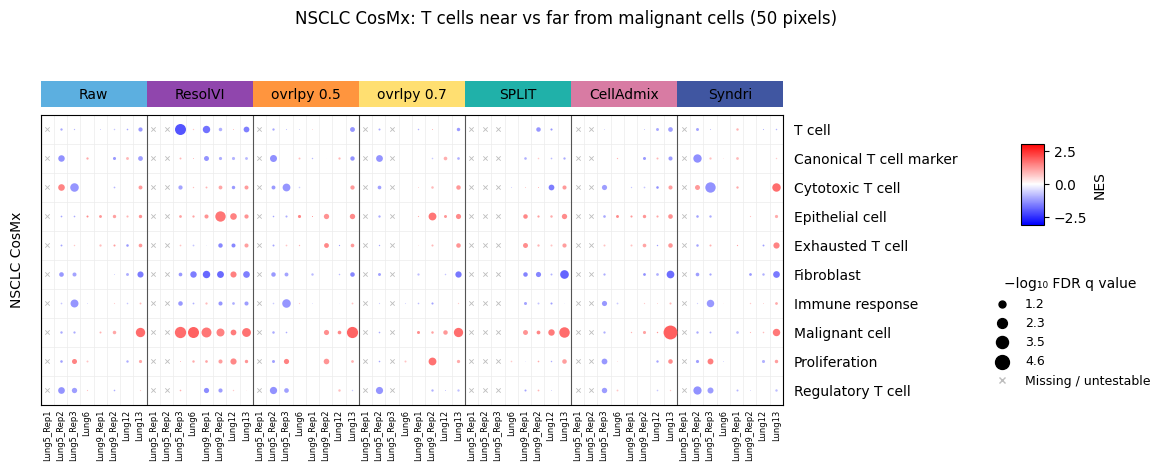

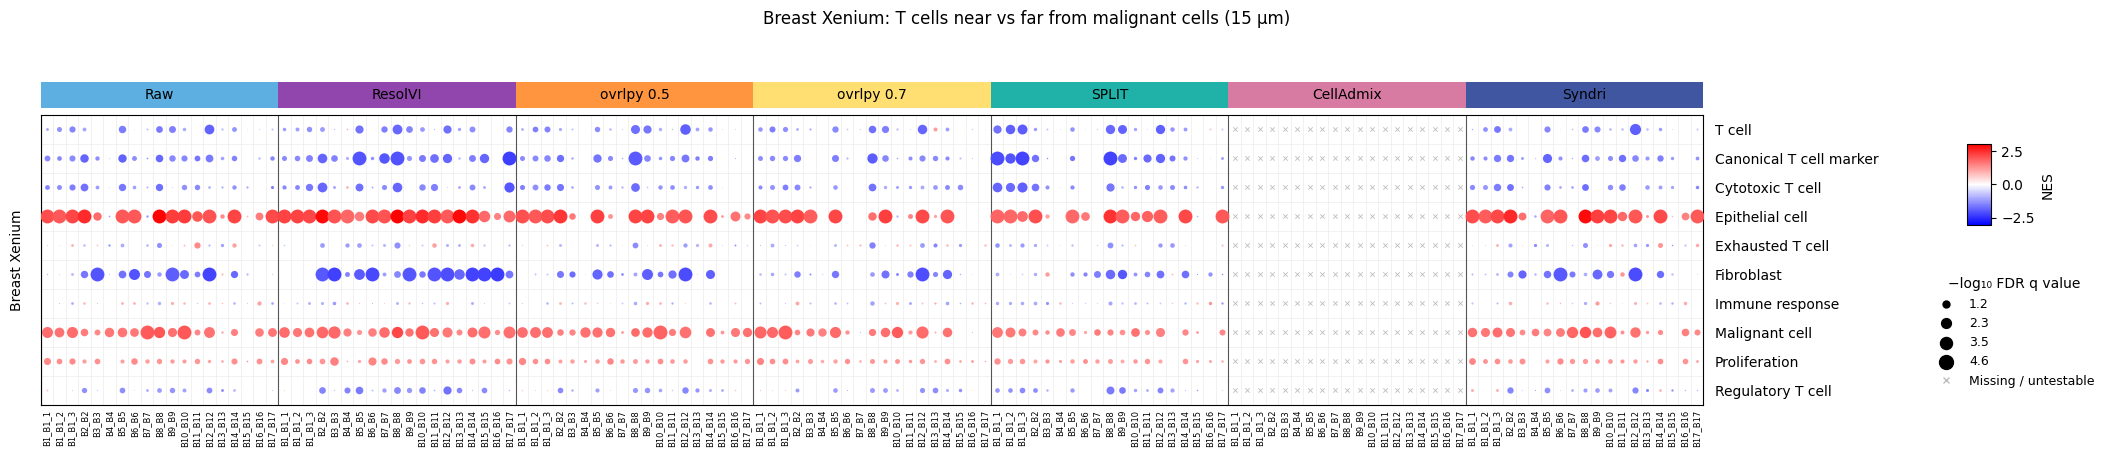

In [5]:
def save_new_figure(fig, stem):
    i = 1
    while any((RUN_DIR / f'{stem}_{i}.{ext}').exists() for ext in ['pdf','png']): i += 1
    for ext in ['pdf','png']: fig.savefig(RUN_DIR / f'{stem}_{i}.{ext}', dpi=300, bbox_inches='tight')


def plot_enrichment(enrichment):
    if enrichment.empty:
        print('No testable enrichment results. Inspect status_table.')
        return []
    frame = enrichment.copy()
    frame['NES'] = pd.to_numeric(frame['NES'], errors='raise')
    frame['FDR q-val'] = pd.to_numeric(frame['FDR q-val'], errors='raise')
    positive_q = frame.loc[frame['FDR q-val'] > 0, 'FDR q-val']
    q_floor = float(positive_q.min() * 0.1) if len(positive_q) else 1. / (PERMUTATIONS * 10)
    frame['logq'] = -np.log10(frame['FDR q-val'].clip(lower=q_floor, upper=1.))
    limit = max(float(frame.NES.abs().max()), 1e-6)
    norm = TwoSlopeNorm(vmin=-limit, vcenter=0., vmax=limit)
    size_max = max(float(frame.logq.max()), 1.)
    figures = []
    for dataset in DATASETS:
        slices = [p.stem for p in inputs[dataset]]
        n = len(slices)
        fig = plt.figure(figsize=(max(14, n*len(METHODS)*0.16+5), 5.0))
        grid = fig.add_gridspec(1,2, width_ratios=[max(10, n*len(METHODS)*0.16), 4.4], wspace=0.03)
        ax = fig.add_subplot(grid[0]); legend_ax = fig.add_subplot(grid[1]); legend_ax.axis('off')
        for m, method in enumerate(METHODS):
            offset = m*n
            ax.add_patch(Rectangle((offset-.5, 1.025), n, .09, transform=ax.get_xaxis_transform(),
                                   color=COLORS[method], clip_on=False, linewidth=0))
            ax.text(offset+(n-1)/2, 1.07, method, transform=ax.get_xaxis_transform(),
                    ha='center', va='center', color='black', fontsize=10)
            for j, slice_name in enumerate(slices):
                subset = frame.loc[(frame.dataset==dataset)&(frame.method==method)&(frame['slice']==slice_name)].set_index('Term')
                if not subset.index.is_unique: raise ValueError('Duplicate enrichment terms')
                for y, term in enumerate(TERMS):
                    x = offset+j
                    if term not in subset.index or not np.isfinite(subset.loc[term,'NES']):
                        ax.scatter(x, y, s=10, marker='x', color='#bdbdbd', linewidths=.6, zorder=3)
                    else:
                        row = subset.loc[term]
                        ax.scatter(x, y, s=100*row.logq/size_max, c=[row.NES], cmap='bwr', norm=norm, linewidths=0, zorder=3)
            ax.axvline(offset-.5, color='#555555', linewidth=.8)
        ax.set_xlim(-.5, n*len(METHODS)-.5); ax.set_ylim(len(TERMS)-.5, -.5)
        ax.set_yticks(range(len(TERMS)), labels=[s[0].upper()+s[1:] for s in TERMS])
        ax.yaxis.tick_right(); ax.tick_params(axis='y', length=0, labelsize=10, pad=8)
        ax.set_xticks(np.arange(n*len(METHODS)), labels=([sample_label(s) for s in slices]*len(METHODS)) if SHOW_SAMPLE_LABELS else ['']*(n*len(METHODS)))
        ax.tick_params(axis='x', labelsize=6, rotation=90, length=0)
        ax.set_xticks(np.arange(-.5,n*len(METHODS),1), minor=True)
        ax.set_yticks(np.arange(-.5,len(TERMS),1), minor=True)
        ax.grid(which='minor', color='#ececec', linewidth=.5); ax.tick_params(which='minor', length=0)
        ax.set_ylabel(CONFIG[dataset]['title'], labelpad=12)
        # Leave the left part of the legend panel free for right-side row labels.
        cax = legend_ax.inset_axes([.68,.62,.07,.28])
        fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='bwr'), cax=cax, label='NES')
        levels = np.linspace(size_max/4, size_max, 4)
        handles = [plt.scatter([],[],s=100*v/size_max,color='black',label=f'{v:.2g}') for v in levels]
        handles += [plt.Line2D([],[], marker='x', color='#bdbdbd', linestyle='', markersize=5,label='Missing / untestable')]
        legend_ax.legend(handles=handles, title='−log₁₀ FDR q value', loc='center left', bbox_to_anchor=(.55,.25), frameon=False, fontsize=9)
        fig.suptitle(f"{CONFIG[dataset]['title']}: T cells near vs far from malignant cells "
                     f"({CONFIG[dataset]['radius']:g} {CONFIG[dataset]['units']})", y=1.04, fontsize=12)
        fig.subplots_adjust(bottom=.25, top=.83)
        save_new_figure(fig, f'{dataset}_tcell_marker_enrichment')
        plt.show()
        figures.append(fig)
    return figures

figures = plot_enrichment(enrichment)
